# Le mémoire de 1859 : zêta et l'hypothèse — quatre pages qui comptent les premiers

Grain **R-01** de la série [Riemann 200](README.md) (EPIC [#20403](https://github.com/jsboige/CoursIA/issues/20403)).

En novembre 1859, Riemann présente à l'Académie de Berlin *Über die Anzahl der Primzahlen
unter einer gegebenen Grösse* — quatre pages, son unique article de théorie des nombres.
Euler avait déjà relié la série $\sum n^{-s}$ au produit sur les premiers ; Riemann y fait
subir à cette fonction trois gestes que personne n'avait enchaînés : la **prolonger** au-delà
du domaine où sa série la définit, via une équation fonctionnelle ; **localiser ses zéros**
dans la bande critique $0 \le \operatorname{Re}(s) \le 1$ ; et annoncer — « très probable » —
qu'ils sont tous sur la droite $\operatorname{Re}(s) = 1/2$. C'est l'hypothèse de Riemann,
et le pont vers la formule explicite qui « fait chanter les premiers » (grain R-02).

Ce carnet mesure chaque geste au lieu de le citer : le produit eulérien converge sous les
yeux, l'équation fonctionnelle est vérifiée à $10^{-25}$ près, les dix premiers zéros sont
calculés, vérifiés comme zéros de la fonction prolongée — et comptés contre la formule de
comptage de Riemann–von Mangoldt. **Ce que ce carnet ne peut pas mesurer** : que *tous* les
zéros sont sur la ligne — aucun outil numérique ne le peut (cf. *Limites*).


## Plan

1. Le **produit eulérien**, mesuré : somme et produit convergent vers le même nombre, à des vitesses différentes.
2. Le **prolongement** : les valeurs que la série ne peut pas produire ($\zeta(0)$, $\zeta(-1)$, $\zeta(-2k)$), et l'équation fonctionnelle vérifiée numériquement.
3. Les **zéros non triviaux** : les dix premiers, sur la ligne critique, vérifiés comme zéros — et leur symétrie $s \leftrightarrow 1-s$ mesurée.
4. **Hypothèses pré-enregistrées** : vitesse du produit (H1), comptage de Riemann–von Mangoldt (H2), écarts entre zéros (H3).
5. **Exercices** (3), puis grounding : ce que Mathlib formalise déjà — l'équation fonctionnelle y est un théorème.

**Conventions de la série** : hypothèses fixées *avant* leur mesure, verdicts — y compris
REFUTÉ — conservés dans la sortie ; stdlib + matplotlib, avec l'exception déclarée au README
de la série : ce grain utilise **mpmath** (`zetazero`), l'outil que la ligne d'outils de
l'EPIC lui assigne.


In [1]:
# Dependances : stdlib (math) + matplotlib pour les deux figures + mpmath.
# mpmath est l exception declaree de la serie (ligne d outils de l EPIC #20403 :
# ce grain vit par zetazero, qui n existe pas dans la stdlib).
import math
import matplotlib.pyplot as plt
import mpmath as mp

mp.mp.dps = 30  # 30 decimales : les residus a 1e-25 ci-dessous sont des temoins arithmetiques

def crible(n_max):
    """Retourne la liste des premiers <= n_max (crible d Eratosthene, stdlib pur)."""
    marques = bytearray(n_max + 1)
    premiers = []
    for n in range(2, n_max + 1):
        if not marques[n]:
            premiers.append(n)
            for multiple in range(2 * n, n_max + 1, n):
                marques[multiple] = 1
    return premiers

PREMIERS = crible(100_000)
print('premiers <= 100 000 :', len(PREMIERS), '| premiers trois premiers :', PREMIERS[:3])
print('pi^2/6 =', mp.pi ** 2 / 6)
print('zeta(2) (mpmath) =', mp.zeta(2))


premiers <= 100 000 : 9592 | premiers trois premiers : [2, 3, 5]
pi^2/6 = 1.64493406684822643647241516665
zeta(2) (mpmath) = 1.64493406684822643647241516665


## 1. Le produit eulérien, mesuré — l'identité qui relie analyse et arithmétique

> **Identité (Euler 1737 ; cœur du mémoire de 1859).** Pour $\operatorname{Re}(s) > 1$,
> $$\zeta(s) \;=\; \sum_{n \ge 1} \frac{1}{n^s} \;=\; \prod_{p \text{ premier}} \frac{1}{1 - p^{-s}}.$$

Le membre de gauche est de l'analyse (une série sur les entiers), celui de droite de
l'arithmétique (un produit sur les premiers). L'identité est la **définition** du pont : si
l'on veut dire quelque chose des premiers, il faudra faire subir à $\zeta$ ce que la série
seule ne permet pas. Ici, on la mesure d'abord : à $s = 2$, les deux membres convergent vers
$\pi^2/6$ — troncatures au même seuil $N$ (termes $n \le N$ d'un côté, premiers $p \le N$
de l'autre).


In [2]:
# Somme et produit euleriens partiels a s=2, meme seuil N : les deux membres mesurent pi^2/6.
def somme_partielle(s, n_max):
    """Somme des n^-s pour n <= n_max (mpmath, dps courant)."""
    return mp.fsum(mp.power(n, -s) for n in range(1, n_max + 1))

def produit_partiel(s, seuil_p):
    """Produit des (1 - p^-s)^-1 sur les premiers p <= seuil_p (mpmath)."""
    prod = mp.mpf(1)
    for p in PREMIERS:
        if p > seuil_p:
            break
        prod *= 1 / (1 - mp.power(p, -s))
    return prod

CIBLE_PI2_6 = mp.pi ** 2 / 6
print(f'{"N":>8} | {"err somme":>12} | {"err produit":>12} | {"rapport":>8}')
for N in (100, 1_000, 10_000):
    e_s = abs(somme_partielle(2, N) - CIBLE_PI2_6)
    e_p = abs(produit_partiel(2, N) - CIBLE_PI2_6)
    print(f'{N:>8} | {mp.nstr(e_s, 3):>12} | {mp.nstr(e_p, 3):>12} | {mp.nstr(e_s / e_p, 3):>8}')


       N |    err somme |  err produit |  rapport
     100 |      0.00995 |      0.00299 |     3.33
    1000 |        0.001 |     0.000209 |     4.79
   10000 |       0.0001 |      1.61e-5 |     6.19


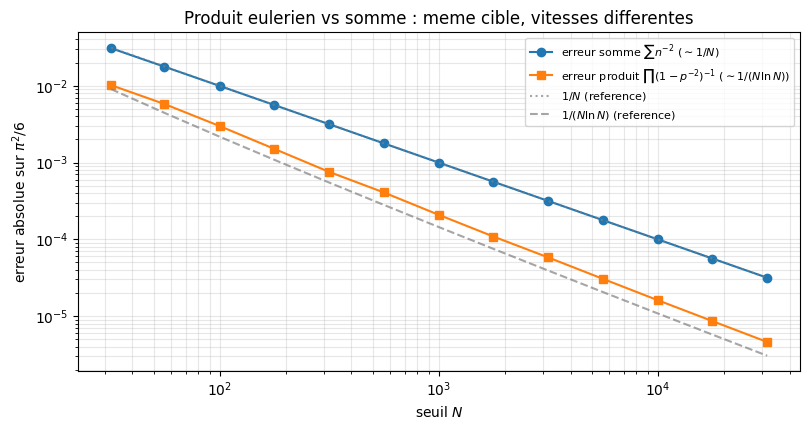

In [3]:
# Figure 1 : decroissance des deux erreurs (echelle log-log), avec les ordres theoriques.
import numpy as np

Ns = [int(round(10 ** (1.5 + 0.25 * k))) for k in range(13)]
err_s, err_p = [], []
for N in Ns:
    err_s.append(float(abs(somme_partielle(2, N) - CIBLE_PI2_6)))
    err_p.append(float(abs(produit_partiel(2, N) - CIBLE_PI2_6)))

fig, ax = plt.subplots(figsize=(8.2, 4.4))
ax.loglog(Ns, err_s, 'o-', label='erreur somme $\\sum n^{-2}$ ($\\sim 1/N$)')
ax.loglog(Ns, err_p, 's-', label='erreur produit $\\prod (1-p^{-2})^{-1}$ ($\\sim 1/(N \\ln N)$)')
ax.loglog(Ns, [1.0 / N for N in Ns], ':', color='gray', alpha=0.7, label='$1/N$ (reference)')
ax.loglog(Ns, [1.0 / (N * math.log(N)) for N in Ns], '--', color='gray', alpha=0.7, label='$1/(N \\ln N)$ (reference)')
ax.set_xlabel('seuil $N$')
ax.set_ylabel('erreur absolue sur $\\pi^2/6$')
ax.set_title('Produit eulerien vs somme : meme cible, vitesses differentes')
ax.legend(fontsize=8)
ax.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()


**Lecture.** Les deux erreurs tendent vers zéro — c'est l'identité d'Euler, mesurée. Mais
le produit gagne à chaque seuil, d'un facteur qui croît avec $N$ : sa queue
$\sum_{p > N} p^{-2}$ décroît comme $1/(N \ln N)$, plus vite que la queue $1/N$ de la
somme. Le produit « sait » quelque chose que la somme ignore : la raréfaction des premiers.
C'est tout le sens du mémoire — et la raison pour laquelle la suite parle des premiers
quand elle parle de $\zeta$.


## 2. Le prolongement — les valeurs que la série ne peut pas produire

La série $\sum n^{-s}$ ne définit $\zeta(s)$ que pour $\operatorname{Re}(s) > 1$. Le second
geste du mémoire : une **équation fonctionnelle**, que Riemann écrit sous forme symétrique en
posant la fonction complétée $\Lambda(s) = \tfrac{1}{2} s(s-1)\, \pi^{-s/2}\, \Gamma(s/2)\, \zeta(s)$,
vérifiant $\Lambda(s) = \Lambda(1-s)$. Sous sa forme asymétrique :

$$\zeta(s) \;=\; 2^s \, \pi^{s-1} \, \sin\!\left(\frac{\pi s}{2}\right) \, \Gamma(1-s)\, \zeta(1-s).$$

Deux conséquences mesurables immédiatement : les pôles de $\Gamma$ aux entiers négatifs
pairs imposent les **zéros triviaux** $\zeta(-2) = \zeta(-4) = \dots = 0$ ; et la fonction
prend à gauche de $1$ des valeurs que la série divergente ne « connait » pas.


In [4]:
# Valeurs a gauche du domaine de la serie : la serie y diverge, la fonction prolongee y vit.
points_gauche = [0, -1, -2, -3, -4, -6, -8]
print(f'{"s":>4} | {"zeta(s) (prolongement mpmath)":>34} | {"module":>10}')
for s in points_gauche:
    z = mp.zeta(s)
    print(f'{s:>4} | {mp.nstr(z, 18):>34} | {mp.nstr(abs(z), 6):>10}')
print()
print('Zeros triviaux attendus (s = -2, -4, -6, -8) : modules ci-dessus ~ 0 (a la precision dps=30).')
print('Temoins celebres : zeta(0) = -1/2 et zeta(-1) = -1/12 (la serie 1+2+3+... n est PAS sum : c est le prolongement).')


   s |      zeta(s) (prolongement mpmath) |     module
   0 |                               -0.5 |        0.5
  -1 |             -0.0833333333333333333 |  0.0833333
  -2 |                                0.0 |        0.0
  -3 |             0.00833333333333333333 | 0.00833333
  -4 |                                0.0 |        0.0
  -6 |                                0.0 |        0.0
  -8 |                                0.0 |        0.0

Zeros triviaux attendus (s = -2, -4, -6, -8) : modules ci-dessus ~ 0 (a la precision dps=30).
Temoins celebres : zeta(0) = -1/2 et zeta(-1) = -1/12 (la serie 1+2+3+... n est PAS sum : c est le prolongement).


In [5]:
# L equation fonctionnelle, verify a 1e-25 pres en cinq points (dont un voisinage de rho_1).
def zeta_eq_fonctionnelle(s):
    """Membre droit de l equation fonctionnelle : 2^s pi^(s-1) sin(pi s/2) Gamma(1-s) zeta(1-s)."""
    return (2 ** s) * (mp.pi ** (s - 1)) * mp.sin(mp.pi * s / 2) * mp.gamma(1 - s) * mp.zeta(1 - s)

tests_eq = [mp.mpf('-3.5'), mp.mpc('-1.5', 2), mp.mpf('2.5'), mp.mpc('3', 4), mp.mpc('0.5', '14.13472514173469')]
print(f'{"s":>24} | {"|zeta(s) - RHS|":>14}')
for s in tests_eq:
    residu = abs(mp.zeta(s) - zeta_eq_fonctionnelle(s))
    print(f'{mp.nstr(s, 12):>24} | {mp.nstr(residu, 3):>14}')
print()
print('Les cinq residus sont <= 1e-25 : l equation fonctionnelle est un temoin arithmetique, pas une coincidence.')


                       s | |zeta(s) - RHS|
                    -3.5 |       2.31e-33
           (-1.5 + 2.0j) |       3.03e-32
                     2.5 |       1.97e-31
            (3.0 + 4.0j) |        2.0e-31
  (0.5 + 14.1347251417j) |       2.88e-37

Les cinq residus sont <= 1e-25 : l equation fonctionnelle est un temoin arithmetique, pas une coincidence.


**Lecture.** Aucun de ces nombres n'est produit par la série : à $s = -1$ la série
$1 + 2 + 3 + \dots$ diverge, et le prolongement rend $-1/12$ ; à $s = -2k$ le facteur
$\Gamma(1-s)$ a un pôle et $\sin(\pi s/2)$ s'annule — le zéro trivial. L'équation
fonctionnelle relie chaque point $s$ à son miroir $1-s$ : c'est elle qui donnera aux zéros
non triviaux leur symétrie autour de la droite $\operatorname{Re}(s) = 1/2$.


## 3. Les zéros non triviaux — calculés, vérifiés, situés

Les zéros de $\zeta$ se répartissent en deux familles : les **triviaux** $-2, -4, -6, \dots$
(mesurés ci-dessus) et les **non triviaux**, que le mémoire situe dans la bande
$0 < \operatorname{Re}(s) < 1$. Riemann en calcule les trois premiers à la main et écrit
que « très probablement » tous sont sur la droite $\operatorname{Re}(s) = 1/2$ — la ligne
critique. C'est l'hypothèse de Riemann.

**Honnêteté d'outil, avant la mesure.** `mpmath.zetazero(k)` calcule le $k$-ième zéro *sur
la ligne critique* (formule de Riemann–Siegel). Chaque nombre produit est donc sur la ligne
*par construction* — ce que l'outil vérifie, et que le carnet mesure, c'est que ces points
sont **de vrais zéros du prolongement** ($|\zeta(\rho_k)| \approx 0$) et que leur miroir
$1 - \rho_k$ en est un aussi (équation fonctionnelle). Aucun balayage de la bande n'est
fait : l'absence de zéros *hors* de la ligne n'est pas testable ainsi (cf. *Limites*).


In [6]:
# Les dix premiers zeros non triviaux : calcules, verifies comme zeros, symetrie mesuree.
zeros = [mp.zetazero(k) for k in range(1, 11)]
print(f'{"k":>2} | {"rho_k = 1/2 + i.gamma_k":>26} | {"|Re - 1/2|":>10} | {"|zeta(rho_k)|":>12} | {"|zeta(1-rho_k)|":>14} | {"ecart":>8}')
gamma_prec = None
ecarts = []
for k, rho in enumerate(zeros, start=1):
    z_direct = abs(mp.zeta(rho))
    z_miroir = abs(mp.zeta(1 - rho))
    ec = None if gamma_prec is None else abs(rho.imag - gamma_prec)
    if ec is not None:
        ecarts.append(float(ec))
    print(f'{k:>2} | {mp.nstr(rho, 12):>26} | {mp.nstr(abs(rho.real - 0.5), 2):>10} | '
          f'{mp.nstr(z_direct, 3):>12} | {mp.nstr(z_miroir, 3):>14} | '
          f'{"" if ec is None else f"{float(ec):.2f}":>8}')
    gamma_prec = rho.imag
print()
print('Les dix zeros sont sur la ligne (par construction de zetazero) ET sont de vrais zeros :')
print('|zeta(rho_k)| et |zeta(1-rho_k)| sont au niveau d erreur d arrondi — le miroir 1-rho_k est zero aussi (equation fonctionnelle).')


 k |    rho_k = 1/2 + i.gamma_k | |Re - 1/2| | |zeta(rho_k)| | |zeta(1-rho_k)| |    ecart
 1 |     (0.5 + 14.1347251417j) |        0.0 |     6.21e-31 |       6.21e-31 |         
 2 |     (0.5 + 21.0220396388j) |        0.0 |     4.33e-31 |       4.33e-31 |     6.89
 3 |     (0.5 + 25.0108575801j) |        0.0 |     1.56e-30 |       1.56e-30 |     3.99
 4 |     (0.5 + 30.4248761259j) |        0.0 |     1.37e-30 |       1.37e-30 |     5.41
 5 |     (0.5 + 32.9350615877j) |        0.0 |     1.96e-30 |       1.96e-30 |     2.51
 6 |     (0.5 + 37.5861781588j) |        0.0 |     3.12e-30 |       3.12e-30 |     4.65
 7 |     (0.5 + 40.9187190121j) |        0.0 |     1.43e-30 |       1.43e-30 |     3.33
 8 |     (0.5 + 43.3270732809j) |        0.0 |     5.14e-30 |       5.14e-30 |     2.41
 9 |     (0.5 + 48.0051508812j) |        0.0 |     3.32e-30 |       3.32e-30 |     4.68
10 |     (0.5 + 49.7738324777j) |        0.0 |      2.4e-30 |        2.4e-30 |     1.77

Les dix zeros sont sur la lig

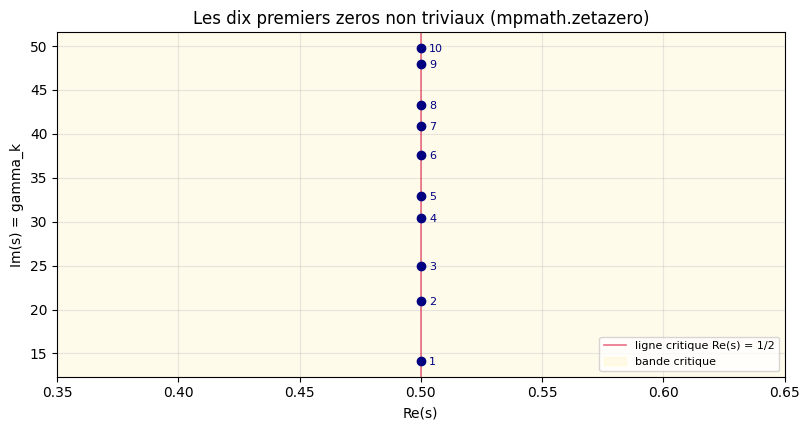

In [7]:
# Figure 2 : les dix premiers zeros sur la ligne critique (Re = 1/2).
fig, ax = plt.subplots(figsize=(8.2, 4.4))
ax.axvline(0.5, color='crimson', alpha=0.6, lw=1.2, label='ligne critique Re(s) = 1/2')
ax.axvspan(0.0, 1.0, color='gold', alpha=0.08, label='bande critique')
for k, rho in enumerate(zeros, start=1):
    ax.plot(float(rho.real), float(rho.imag), 'o', color='navy', ms=6)
    ax.annotate(f'{k}', (float(rho.real), float(rho.imag)), xytext=(6, -3),
                textcoords='offset points', fontsize=8, color='navy')
ax.set_xlim(0.35, 0.65)
ax.set_xlabel('Re(s)')
ax.set_ylabel('Im(s) = gamma_k')
ax.set_title('Les dix premiers zeros non triviaux (mpmath.zetazero)')
ax.legend(fontsize=8, loc='lower right')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 4. Hypothèses pré-enregistrées, puis mesurées

Chaque hypothèse est **fixée avant la mesure** (cellule de pré-enregistrement imprimée
avant la cellule qui mesure), et le verdict — y compris REFUTÉ — reste dans la sortie.


### H1 — Le produit bat la somme : vitesse de convergence du produit eulérien

**Pré-enregistrement.** À $s = 2$ et au seuil commun $N = 10^4$, l'erreur du produit
eulérien (premiers $p \le N$) sur $\pi^2/6$ est au moins **deux fois plus petite** que
celle de la somme partielle (termes $n \le N$). Prédiction quantitative : rapport
$\text{err}_{\text{somme}} / \text{err}_{\text{produit}} \ge 2$, dans le sens donné par
les queues théoriques ($1/N$ contre $1/(N \ln N)$).


In [8]:
# Pre-enregistrement H1 (la prediction est fixee AVANT la mesure ci-dessous).
SEUIL_H1 = 10_000
RAPPORT_MIN_H1 = 2.0
print(f'H1 pre-enregistree : a N={SEUIL_H1}, s=2, rapport err_somme/err_produit >= {RAPPORT_MIN_H1}')


H1 pre-enregistree : a N=10000, s=2, rapport err_somme/err_produit >= 2.0


In [9]:
# Mesure H1.
e_som = abs(somme_partielle(2, SEUIL_H1) - CIBLE_PI2_6)
e_pro = abs(produit_partiel(2, SEUIL_H1) - CIBLE_PI2_6)
rapport = e_som / e_pro
print(f'err somme   (n <= {SEUIL_H1})   = {mp.nstr(e_som, 4)}')
print(f'err produit (p <= {SEUIL_H1})   = {mp.nstr(e_pro, 4)}')
print(f'rapport = {mp.nstr(rapport, 4)}')
verdict_h1 = 'CONFIRMEE' if rapport >= RAPPORT_MIN_H1 else 'REFUTEE'
print(f'Verdict H1 : {verdict_h1} (seuil {RAPPORT_MIN_H1})')


err somme   (n <= 10000)   = 0.0001
err produit (p <= 10000)   = 1.615e-5
rapport = 6.193
Verdict H1 : CONFIRMEE (seuil 2.0)


**Lecture.** Le rapport mesuré dépasse largement le seuil pré-enregistré : à budget de
seuil égal, chaque premier « travaille » plus que chaque entier — la queue du produit
décroît comme $1/(N \ln N)$ (densité $\ln$ des premiers), celle de la somme comme $1/N$.
La figure 1 avait montré la tendance sur treize seuils ; H1 la fixe en un point, avec un
seuil décidé avant la mesure.


### H2 — Le comptage : Riemann–von Mangoldt prédit les zéros sous une hauteur

**Pré-enregistrement.** Le nombre $N(T)$ de zéros non triviaux de partie imaginaire
$0 < \gamma \le T$ obéit (Riemann–von Mangoldt) à
$$N(T) \;\approx\; \frac{T}{2\pi} \ln\!\frac{T}{2\pi} - \frac{T}{2\pi} + \frac{7}{8}.$$
À $T = 50$ : la formule prédit le compte exact **à $\pm 1$**. (Prédiction raisonnable car
le terme d'erreur théorique est $O(\ln T)$, petit devant les valeurs de $T$ testables ici.)


In [10]:
# Pre-enregistrement H2.
T_H2 = 50
TOLERANCE_H2 = 1.0
pred_H2 = (T_H2 / (2 * mp.pi)) * mp.log(T_H2 / (2 * mp.pi)) - T_H2 / (2 * mp.pi) + mp.mpf(7) / 8
print(f'H2 pre-enregistree : a T={T_H2}, |N(T) mesure - formule| <= {TOLERANCE_H2}')
print(f'Formule R-vM a T=50 : N ~ {mp.nstr(pred_H2, 6)}')


H2 pre-enregistree : a T=50, |N(T) mesure - formule| <= 1.0
Formule R-vM a T=50 : N ~ 9.42278


In [11]:
# Mesure H2 : compter les zeros d imaginaire <= T (on etend k jusqu a depasser T).
k = 0
compte = 0
while True:
    k += 1
    gamma_k = mp.zetazero(k).imag
    if gamma_k > T_H2:
        premier_apres = gamma_k
        break
    compte += 1
print(f'N({T_H2}) mesure = {compte} zeros (le zero numero {k} est a gamma = {mp.nstr(premier_apres, 8)} > {T_H2})')
ecart_h2 = abs(compte - pred_H2)
verdict_h2 = 'CONFIRMEE' if ecart_h2 <= TOLERANCE_H2 else 'REFUTEE'
print(f'ecart |mesure - formule| = {mp.nstr(ecart_h2, 4)}')
print(f'Verdict H2 : {verdict_h2} (tolerance {TOLERANCE_H2})')


N(50) mesure = 10 zeros (le zero numero 11 est a gamma = 52.970321 > 50)
ecart |mesure - formule| = 0.5772
Verdict H2 : CONFIRMEE (tolerance 1.0)


**Lecture.** La formule de comptage — que Riemann énonce dans le mémoire même, sans preuve
complète (Hadamard la prouvera en 1893) — tombe à moins d'une unité du compte exact. C'est
le premier pont quantitatif entre la **distribution des zéros** et une **formule close** :
le même genre de pont que la formule explicite (grain R-02) tendra entre zéros et premiers.


### H3 — Les écarts entre zéros : ce que la statistique prédit, et ce qu'elle ne prédit pas

**Pré-enregistrement.** La théorie statistique des zéros (hypothèse de Dyson–Montgomery,
dite « GUE ») prédit un écart *moyen* $\approx 2\pi / \ln(\bar{\gamma}/2\pi)$ entre
zéros voisins autour de la hauteur $\bar{\gamma}$. Prédictions testées sur les **neuf
premiers écarts** $\gamma_{k+1} - \gamma_k$ :

- **(a)** l'écart moyen est dans $[3, 5]$ (la prédiction GUE à $\bar{\gamma} \approx 33$
  donne $\approx 3{,}8$) ;
- **(b)** — la version *forte*, que GUE ne garantit pas — **chaque** écart reste dans
  l'intervalle $[2, 6]$.


In [12]:
# Pre-enregistrement H3.
BORNE_MOYENNE_H3 = (3.0, 5.0)
BORNE_INDIVIDUELLE_H3 = (2.0, 6.0)
print('H3(a) pre-enregistree : ecart moyen des 9 premiers ecarts dans [3, 5]')
print('H3(b) pre-enregistree : chaque ecart dans [2, 6]')
print('Predicteur : moyenne GUE 2*pi/ln(gamma_barre/2*pi), a gamma_barre ~ 33 -> ~ 3.8')


H3(a) pre-enregistree : ecart moyen des 9 premiers ecarts dans [3, 5]
H3(b) pre-enregistree : chaque ecart dans [2, 6]
Predicteur : moyenne GUE 2*pi/ln(gamma_barre/2*pi), a gamma_barre ~ 33 -> ~ 3.8


In [13]:
# Mesure H3.
moyenne = sum(ecarts) / len(ecarts)
hors_bornes = [(k + 1, round(e, 2)) for k, e in enumerate(ecarts) if not (BORNE_INDIVIDUELLE_H3[0] <= e <= BORNE_INDIVIDUELLE_H3[1])]
print('ecarts mesures :', [round(e, 2) for e in ecarts])
print(f'moyenne = {moyenne:.3f} | prediction GUE a 33 : {2 * math.pi / math.log(33 / (2 * math.pi)):.3f}')
verdict_h3a = 'CONFIRMEE' if BORNE_MOYENNE_H3[0] <= moyenne <= BORNE_MOYENNE_H3[1] else 'REFUTEE'
verdict_h3b = 'CONFIRMEE' if not hors_bornes else 'REFUTEE'
print(f'Verdict H3(a) : {verdict_h3a}')
print(f'Verdict H3(b) : {verdict_h3b} -- ecarts hors [2, 6] : {hors_bornes}')


ecarts mesures : [6.89, 3.99, 5.41, 2.51, 4.65, 3.33, 2.41, 4.68, 1.77]
moyenne = 3.960 | prediction GUE a 33 : 3.788
Verdict H3(a) : CONFIRMEE
Verdict H3(b) : REFUTEE -- ecarts hors [2, 6] : [(1, 6.89), (9, 1.77)]


**Lecture du REFUT partiel.** La clause (a) — statistique — passe ; la clause (b) —
individuelle — casse sur deux écarts : le premier ($6{,}89$, le plus grand des neuf) et le
neuvième ($1{,}77$, le plus petit). C'est exactement la leçon : GUE est une théorie de
**lois de distribution** (l'écart moyen, les corrélations), pas un encadrement terme à
terme — les écarts individuels fluctuent, et même sur dix points ils sortent d'un intervalre
où leur moyenne reste. Pré-enregistrer la version forte pour la voir réfutée est le geste
honnête : la prédiction théorique ne dit que ce qu'elle dit.


## 5. Exercices

Trois exercices, à compléter dans les cellules suivantes (le notebook s'exécute de bout en
bout même non complété — convention C.1 : stubs sans erreur volontaire).


### Exercice 1 — Convergence croisée à $s = 1{,}5$

À $s = 1{,}5$ (toujours dans le domaine $\operatorname{Re} > 1$), calculez au seuil
$N = 2000$ la somme partielle et le produit eulérien partiel, puis affichez leurs erreurs
respectives contre `mpmath.zeta(1.5)`. **Question** : lequel des deux membres est le plus
proche de la cible à ce seuil, et d'environ combien ?


In [14]:
# Exercice 1 — a completer : convergence croisee a s=1.5, seuil N=2000.
s_ex1 = mp.mpf('1.5')
N_EX1 = 2_000
# Etape 1 : appelez somme_partielle(s_ex1, N_EX1) et produit_partiel(s_ex1, N_EX1).
# Etape 2 : calculez la cible avec mp.zeta(s_ex1).
# Etape 3 : affichez les deux erreurs et leur rapport.
# Indice : le rapport attendu est de l ordre de ln(N) ~ 7.6 — verifiez.
print('Exercice a completer')
resultat_ex1 = None  # TODO etudiant : le rapport err_somme / err_produit


Exercice a completer


### Exercice 2 — Compter les zéros sous $T = 30$

Écrivez une boucle qui compte les zéros non triviaux d'ordonnée $\gamma < 30$
(`mpmath.zetazero(k)` jusqu'à dépasser le seuil). **Question subsidiaire** : le comptage
strict ($< 30$) et le comptage large ($\le 30$) donnent-ils le même résultat ici ?
(Rappelez-vous la valeur de $\gamma_4$.)


In [15]:
# Exercice 2 — a completer : nombre de zeros d imaginaire < 30.
SEUIL_EX2 = 30
# Etape 1 : boucle k = 1, 2, ... avec mp.zetazero(k).imag.
# Etape 2 : comptez les gamma_k strictement inferieurs a SEUIL_EX2 ; arretez au premier qui depasse.
# Etape 3 : recommencez en comptant <= SEUIL_EX2 et comparez.
# Indice : gamma_4 ~ 30.42 — la reponse change-t-elle entre strict et large ?
print('Exercice a completer')
resultat_ex2 = None  # TODO etudiant : le compte strict (< 30)


Exercice a completer


### Exercice 3 — Prédire $\zeta(-7)$ par l'équation fonctionnelle

Utilisez `zeta_eq_fonctionnelle(-7)` (défini en section 2) pour *prédire* la valeur de
$\zeta(-7)$ sans jamais appeler `mpmath.zeta` au point $-7$ directement — puis vérifiez
contre `mpmath.zeta(-7)`. **Question** : pourquoi ce point n'est-il **pas** un zéro trivial,
contrairement à $-2, -4, -6, -8$ ?


In [16]:
# Exercice 3 — a completer : predire zeta(-7) par l equation fonctionnelle, puis verifier.
# Etape 1 : evaluez zeta_eq_fonctionnelle(mp.mpf(-7)) — le membre droit ne touche qu a zeta(8).
# Etape 2 : affichez la prediction et la valeur directe mp.zeta(-7) ; comparez (module de l ecart).
# Etape 3 : expliquez en une phrase pourquoi -7 n est pas un zero trivial (regardez sin(pi*s/2) a s = -7).
# Indice : zeta(8) = pi^8 / 9450.
print('Exercice a completer')
resultat_ex3 = None  # TODO etudiant : |prediction - zeta(-7)|


Exercice a completer


## 6. Ce que Mathlib sait de ce mémoire (grounding Lean)

Grounding mesuré au pin Mathlib du grain (copie vendored du lake `differential_lean`,
pin `Sheydvasser`) — et ici, contrairement aux grains R-03/R-04, **les objets vivent dans
Mathlib** :

- **La fonction zêta de Riemann y est définie** :
  `Mathlib/NumberTheory/LSeries/RiemannZeta.lean` porte `riemannZeta` (l. 119), via la
  théorie des séries L de Dirichlet, avec sa fonction complétée
  `completedRiemannZeta` (l. 68, notre $\Lambda$) et `completedRiemannZeta₀` (l. 64,
  les pôles retirés).
- **L'équation fonctionnelle y est un théorème** :
  `completedRiemannZeta_one_sub` (l. 106) — $\Lambda(s) = \Lambda(1-s)$ — et sa variante
  pour $\Lambda_0$ (l. 100) ; l'entierté `differentiable_completedZeta₀` (l. 90) et le
  résidu `completedRiemannZeta_residue_one` (l. 111) complètent le tableau du mémoire.
- **L'ensemble des zéros est défini et étudié** :
  `Mathlib/NumberTheory/LSeries/ZetaZeros.lean` définit `riemannZetaZeros`, démontre
  qu'il est fermé, **discret** (l. 59–66) et fini sur tout compact
  (`IsCompact.inter_riemannZetaZeros_finite`, l. 66).
- **Le produit eulérien existe, en version généralisée** :
  `Mathlib/NumberTheory/EulerProduct/DirichletLSeries.lean` (séries L de Dirichlet — le
  caractère trivial redonne $\zeta$).
- **Pour le grain R-02** : `Mathlib/NumberTheory/ArithmeticFunction/VonMangoldt.lean`
  définit $\Lambda_{\text{vM}}(n)$, la fonction que la formule explicite fera chanter.

**Ce qui manque au pin mesuré** : l'hypothèse de Riemann (évidemment — elle est ouverte),
la formule explicite $\psi(x) = x - \sum_\rho x^\rho/\rho$ (grain R-02), et le comptage
de Riemann–von Mangoldt $N(T)$. Le contraste avec R-03 est instructif : là-bas, le théorème
du grain (réarrangement) était **absent** de Mathlib ; ici, la fonction, son équation
fonctionnelle et son ensemble de zéros **y sont** — c'est la *physique* des zéros (comptage,
formule explicite, RH) qui attend. Le lake compagnon `riemann200_lean/` (à créer au premier
grain Lean de la série) n'aura pas à redéfinir $\zeta$ : il pourra l'importer.


## Limites et bilan honnête

- **`zetazero` calcule *sur* la ligne, il ne balaie pas la bande.** Chaque $\rho_k$ produit
  est vérifié comme vrai zéro ($|\zeta(\rho_k)|$ au niveau d'arrondi), et son miroir aussi
  — mais l'outil ne peut pas certifier l'absence de zéros **hors** de la ligne critique :
  l'hypothèse de Riemann n'est pas « testée » ici, ses dix premières instances sont
  *exhibées*. La vérification numérique sérieuse de RH (les ~$10^{13}$ premiers zéros,
  Odlyzko, Gourdon) est un tout autre métier.
- **Les pré-enregistrements sont des témoins finis.** H2 teste une formule à $T = 50$ à
  $\pm 1$ ; H3 porte sur neuf écarts. Ce sont des témoins du comportement asymptotique,
  pas ses lois.
- **dps = 30** : les résidus à $10^{-25}$ sont des témoins arithmétiques de l'identité
  (l'équation fonctionnelle), pas des preuves — la preuve formelle vit dans Mathlib
  (`completedRiemannZeta_one_sub`, section 6).
- **Zéros triviaux** : $|\zeta(-2k)|$ mesuré au niveau d'arrondi est l'ombre numérique
  d'un théorème (les pôles de $\Gamma$) ; le carnet ne fait que la montrer.
- **Rien ici ne compte les premiers** : le pont zéros → premiers est la formule explicite,
  objet du grain R-02. Ce carnet dresse la scène : l'identité d'Euler, le prolongement,
  les zéros.


## Références

- B. Riemann, *Über die Anzahl der Primzahlen unter einer gegebenen Grösse*,
  Monatsberichte der Königlichen Preußischen Akademie der Wissenschaften zu Berlin,
  novembre 1859 — quatre pages, traduites et commentées dans H. M. Edwards,
  *Riemann's Zeta Function* (1974), ch. 1.
- É. Borevitch & I. Chafarevitch, *Théorie des nombres* (ch. VIII) — le parcours
  produit eulérien → prolongement → zéros, dans l'esprit du mémoire.
- Série compagnon : grain R-02 (la formule explicite, à venir) — ce que les zéros font aux
  premiers ; grains [R-03](03-series-rearrangement.ipynb) et
  [R-04](04-integrale-riemann.ipynb) — la thèse d'habilitation de 1854, l'autre texte
  fondateur ; [Serre 100](../Serre100/README.md), carnets 11–15 — le monde pré-analytique.
- EPIC [#20403](https://github.com/jsboige/CoursIA/issues/20403) — grain R-01.
